In [202]:
import torch

In [203]:
def obj_func(x):
    return (1.0 - x[0])**2 + 100.0 * (x[1] - x[0]**2)**2


In [204]:
# Gradient descent
x0 = 2.0
y0 = 2.0
x = torch.tensor([x0, y0], requires_grad=True)

iters = 100
lr = .001

gd_buffer = []

for iter in range(iters):
    x.grad = None

    gd_buffer.append(x.detach().clone())

    loss = obj_func(x)
    print(loss)
    loss.backward()
    
    with torch.no_grad():
        x -= lr * x.grad

tensor(401., grad_fn=<AddBackward0>)
tensor(502.8377, grad_fn=<AddBackward0>)
tensor(190.5120, grad_fn=<AddBackward0>)
tensor(8.8864, grad_fn=<AddBackward0>)
tensor(1.2781, grad_fn=<AddBackward0>)
tensor(0.4411, grad_fn=<AddBackward0>)
tensor(0.1596, grad_fn=<AddBackward0>)
tensor(0.0985, grad_fn=<AddBackward0>)
tensor(0.0817, grad_fn=<AddBackward0>)
tensor(0.0776, grad_fn=<AddBackward0>)
tensor(0.0765, grad_fn=<AddBackward0>)
tensor(0.0762, grad_fn=<AddBackward0>)
tensor(0.0761, grad_fn=<AddBackward0>)
tensor(0.0760, grad_fn=<AddBackward0>)
tensor(0.0760, grad_fn=<AddBackward0>)
tensor(0.0760, grad_fn=<AddBackward0>)
tensor(0.0759, grad_fn=<AddBackward0>)
tensor(0.0759, grad_fn=<AddBackward0>)
tensor(0.0758, grad_fn=<AddBackward0>)
tensor(0.0758, grad_fn=<AddBackward0>)
tensor(0.0758, grad_fn=<AddBackward0>)
tensor(0.0757, grad_fn=<AddBackward0>)
tensor(0.0757, grad_fn=<AddBackward0>)
tensor(0.0756, grad_fn=<AddBackward0>)
tensor(0.0756, grad_fn=<AddBackward0>)
tensor(0.0756, grad_fn=

In [205]:
from torch.autograd.functional import hessian
from torch.linalg import inv
# Full Hessian
x0 = 2.0
y0 = 2.0
x = torch.tensor([x0, y0], requires_grad=True)

full_hessian_buffer = []

iters = 10
lr = 1

for iter in range(iters):
    x.grad = None

    full_hessian_buffer.append(x.detach().clone())

    loss = obj_func(x)
    print(loss)
    loss.backward()
    H = torch.tensor(hessian(obj_func, x))

    with torch.no_grad():
        g = x.grad
        p = -inv(H) @ g
        x += lr * p


tensor(401., grad_fn=<AddBackward0>)
tensor(0.9950, grad_fn=<AddBackward0>)
tensor(98.5094, grad_fn=<AddBackward0>)
tensor(1.5554e-06, grad_fn=<AddBackward0>)
tensor(2.4017e-10, grad_fn=<AddBackward0>)
tensor(0., grad_fn=<AddBackward0>)
tensor(0., grad_fn=<AddBackward0>)
tensor(0., grad_fn=<AddBackward0>)
tensor(0., grad_fn=<AddBackward0>)
tensor(0., grad_fn=<AddBackward0>)


C:\Users\kpjon\AppData\Local\Temp\ipykernel_6728\1747219821.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  H = torch.tensor(hessian(obj_func, x))


In [206]:
from torch.autograd.functional import hessian
from torch.linalg import inv
# Full Hessian w/ backtracking line search
x0 = 2.0
y0 = 2.0
x = torch.tensor([x0, y0], requires_grad=True)

fh_backtracking_buffer = []

iters = 20
lr = 1

def backtracking_line_search(p, grad, c1=0.1, initial_lr=1):
    alpha = initial_lr
    while obj_func(x + alpha * p) > \
        obj_func(x) + c1 * alpha * torch.dot(grad, p): # backtracking part
        
        alpha /= 2
    return alpha

for iter in range(iters):
    x.grad = None

    fh_backtracking_buffer.append(x.detach().clone())

    loss = obj_func(x)
    print(loss)
    loss.backward()
    H = torch.tensor(hessian(obj_func, x))

    with torch.no_grad():
        g = x.grad
        p = -inv(H) @ g
        alpha = backtracking_line_search(p, g)
        print(alpha)
        x += alpha * p


tensor(401., grad_fn=<AddBackward0>)
1
tensor(0.9950, grad_fn=<AddBackward0>)
0.25
tensor(0.9450, grad_fn=<AddBackward0>)
1
tensor(0.4807, grad_fn=<AddBackward0>)
0.25
tensor(0.3621, grad_fn=<AddBackward0>)
1
tensor(0.2444, grad_fn=<AddBackward0>)
1
tensor(0.1300, grad_fn=<AddBackward0>)
0.5
tensor(0.0832, grad_fn=<AddBackward0>)
1
tensor(0.0390, grad_fn=<AddBackward0>)
1
tensor(0.0147, grad_fn=<AddBackward0>)
1
tensor(0.0040, grad_fn=<AddBackward0>)
1
tensor(0.0006, grad_fn=<AddBackward0>)
1
tensor(2.4316e-05, grad_fn=<AddBackward0>)
1
tensor(6.7204e-08, grad_fn=<AddBackward0>)
1
tensor(1.7764e-12, grad_fn=<AddBackward0>)
1
tensor(0., grad_fn=<AddBackward0>)
1
tensor(0., grad_fn=<AddBackward0>)
1
tensor(0., grad_fn=<AddBackward0>)
1
tensor(0., grad_fn=<AddBackward0>)
1
tensor(0., grad_fn=<AddBackward0>)
1


C:\Users\kpjon\AppData\Local\Temp\ipykernel_6728\1438305732.py:29: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  H = torch.tensor(hessian(obj_func, x))


In [207]:
# BFGS quasi-Newton
x0 = 2.0
y0 = 2.0
x = torch.tensor([x0, y0], requires_grad=True)

bfgs_buffer = []

T = torch.eye(2)
iters = 20

def backtracking_line_search(p, grad, c1=0.1, initial_lr=1):
    alpha = initial_lr
    while obj_func(x + alpha * p) > \
        obj_func(x) + c1 * alpha * torch.dot(grad, p): # backtracking part
        
        alpha /= 2
    return alpha

loss = obj_func(x)
loss.backward()

for iter in range(iters):
    bfgs_buffer.append(x.detach().clone())
    print(loss)
    with torch.no_grad():
        g = x.grad
        p = - T @ g
        alpha = backtracking_line_search(p, g)
        print(alpha)
        x += alpha * p

    x.grad = None

    # update T
    s_k = alpha * p
    loss = obj_func(x)
    loss.backward()
    new_grad = x.grad
    y_k = new_grad - g
    s_k = s_k.view(-1, 1)
    y_k = y_k.view(-1, 1)
    rho_k = 1.0 / (y_k.T @ s_k)
    T = (torch.eye(2) - rho_k * s_k @ y_k.T) @ T @ (torch.eye(2) - rho_k * y_k @ s_k.T) + rho_k * s_k @ s_k.T



tensor(401., grad_fn=<AddBackward0>)
0.00048828125
tensor(50.7903, grad_fn=<AddBackward0>)
0.03125
tensor(1.8666, grad_fn=<AddBackward0>)
0.5
tensor(1.0920, grad_fn=<AddBackward0>)
1
tensor(0.0795, grad_fn=<AddBackward0>)
1
tensor(0.0542, grad_fn=<AddBackward0>)
1
tensor(0.0537, grad_fn=<AddBackward0>)
1
tensor(0.0534, grad_fn=<AddBackward0>)
1
tensor(0.0513, grad_fn=<AddBackward0>)
1
tensor(0.0477, grad_fn=<AddBackward0>)
1
tensor(0.0415, grad_fn=<AddBackward0>)
1
tensor(0.0340, grad_fn=<AddBackward0>)
1
tensor(0.0185, grad_fn=<AddBackward0>)
1
tensor(0.0075, grad_fn=<AddBackward0>)
1
tensor(0.0038, grad_fn=<AddBackward0>)
1
tensor(0.0010, grad_fn=<AddBackward0>)
1
tensor(0.0002, grad_fn=<AddBackward0>)
1
tensor(1.1101e-05, grad_fn=<AddBackward0>)
1
tensor(3.1084e-07, grad_fn=<AddBackward0>)
1
tensor(2.2286e-09, grad_fn=<AddBackward0>)
1


In [208]:
from torch.optim.lbfgs import _strong_wolfe

# BFGS with torch's line search
x0 = 2.0
y0 = 2.0
x = torch.tensor([x0, y0], requires_grad=True)

bfgs_wolfe_buffer = []

T = torch.eye(2)
iters = 20

def wolfe_obj_func(val, lr, p):
    # ensure fresh leaf tensor
    x_new = val + lr * p
    x_new = x_new.clone().detach().requires_grad_(True)
    loss = obj_func(x_new)
    loss.backward()
    grad = x_new.grad.clone()

    return loss.detach(), grad

loss = obj_func(x)
loss.backward()
g = x.grad

for iter in range(iters):
    bfgs_wolfe_buffer.append(x.detach().clone())
    print("loss: ", loss)
    p = - T @ g
    loss, g_new, alpha, _ = _strong_wolfe(
        wolfe_obj_func,
        x.detach(),
        1.0,
        p,
        loss,
        g,
        g.dot(p)
    )
    print("alpha: ", alpha)
    with torch.no_grad():
        x += alpha * p

    x.grad = None

    # update T
    s_k = alpha * p
    y_k = g_new - g
    s_k = s_k.view(-1, 1)
    y_k = y_k.view(-1, 1)
    rho_k = 1.0 / (y_k.T @ s_k)
    T = (torch.eye(2) - rho_k * s_k @ y_k.T) @ T @ (torch.eye(2) - rho_k * y_k @ s_k.T) + rho_k * s_k @ s_k.T

    g = g_new



loss:  tensor(401., grad_fn=<AddBackward0>)
alpha:  tensor(0.0026, grad_fn=<SubBackward0>)
loss:  tensor(260.3710)
alpha:  tensor(0.0043, grad_fn=<RsubBackward1>)
loss:  tensor(14.6495)
alpha:  1.0
loss:  tensor(9.5599)
alpha:  10.0
loss:  tensor(9.1742)
alpha:  tensor(0.3725, grad_fn=<RsubBackward1>)
loss:  tensor(8.6978)
alpha:  1.0
loss:  tensor(8.2773)
alpha:  1.0
loss:  tensor(7.4135)
alpha:  1.0
loss:  tensor(6.3511)
alpha:  tensor(0.7255, grad_fn=<RsubBackward1>)
loss:  tensor(5.4978)
alpha:  1.0
loss:  tensor(5.3689)
alpha:  1.0
loss:  tensor(4.7291)
alpha:  1.0
loss:  tensor(4.0382)
alpha:  1.0
loss:  tensor(3.4813)
alpha:  1.0
loss:  tensor(2.7994)
alpha:  tensor(0.3265, grad_fn=<RsubBackward1>)
loss:  tensor(2.4523)
alpha:  1.0
loss:  tensor(2.2835)
alpha:  1.0
loss:  tensor(2.0151)
alpha:  tensor(0.3954, grad_fn=<RsubBackward1>)
loss:  tensor(1.7853)
alpha:  1.0
loss:  tensor(1.5234)
alpha:  1.0


In [209]:
from torch.optim import LBFGS
# torch LBFGS implementation
x0 = 2.0
y0 = 2.0
x = torch.tensor([x0, y0], requires_grad=True)

torch_lbfgs_buffer = []

optimizer = LBFGS([x], lr=1, history_size=10, line_search_fn='strong_wolfe')
iters = 10

for iter in range(iters):
    torch_lbfgs_buffer.append(x.detach().clone())
    def closure():
        optimizer.zero_grad()
        loss = obj_func(x)
        loss.backward()
        return loss
    
    optimizer.step(closure)
print(obj_func(x))
print(optimizer.state)

#uses LBFGS not BFGS, doesn't use backtracking line search

tensor(1.7408e-13, grad_fn=<AddBackward0>)
defaultdict(<class 'dict'>, {tensor([1.0000, 1.0000], requires_grad=True): {'func_evals': 38, 'n_iter': 35, 'al': [tensor(-3.6125e-11), tensor(-1.8033e-09), tensor(-1.9653e-09), tensor(6.0073e-09), tensor(-3.0802e-06), tensor(3.2809e-08), tensor(3.4018e-06), tensor(-0.0001), tensor(-0.0002), tensor(-0.0005)], 'd': tensor([4.1998e-07, 8.3993e-07]), 't': 1, 'old_dirs': [tensor([-5.0090,  2.0633]), tensor([ 2.4277, -1.1488]), tensor([-0.7057,  0.2835]), tensor([-1.8345,  0.8352]), tensor([ 0.7356, -0.3838]), tensor([-0.4410,  0.2059]), tensor([-0.2726,  0.1280]), tensor([-0.0310,  0.0130]), tensor([-0.0284,  0.0142]), tensor([ 0.0090, -0.0046])], 'old_stps': [tensor([-0.0538, -0.1147]), tensor([-0.0433, -0.1022]), tensor([-0.0239, -0.0503]), tensor([-0.0258, -0.0502]), tensor([-0.0238, -0.0510]), tensor([-0.0094, -0.0179]), tensor([-0.0069, -0.0133]), tensor([-0.0024, -0.0047]), tensor([2.7297e-05, 1.2581e-04]), tensor([-7.3838e-05, -1.7059e-04])

In [221]:
state = optimizer.state
state[x]['func_evals']

38

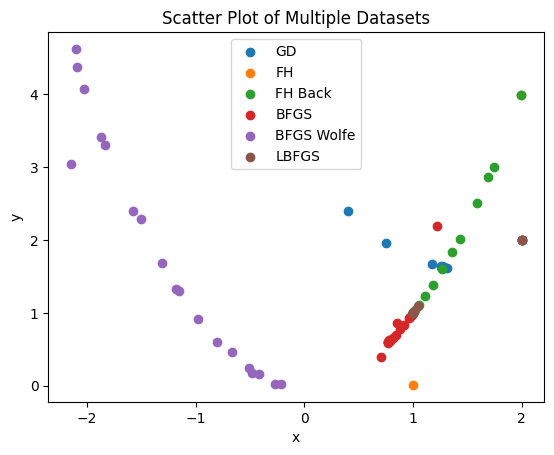

In [210]:
import matplotlib.pyplot as plt

datasets = [gd_buffer, full_hessian_buffer, fh_backtracking_buffer, bfgs_buffer, bfgs_wolfe_buffer,torch_lbfgs_buffer]
labels = ["GD", "FH", "FH Back", "BFGS", "BFGS Wolfe","LBFGS"]

for data, label in zip(datasets, labels):
    xs = [p[0] for p in data]
    ys = [p[1] for p in data]
    plt.scatter(xs, ys, label=label)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Scatter Plot of Multiple Datasets")
plt.legend()
plt.show()

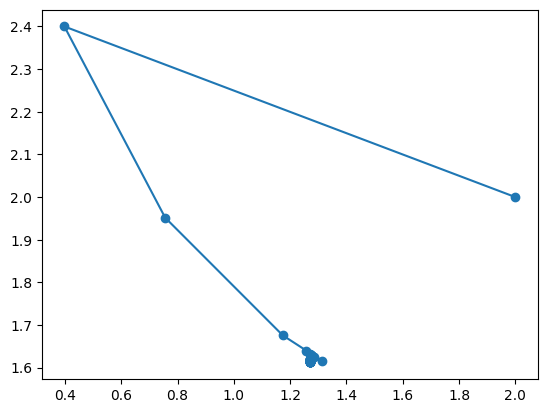

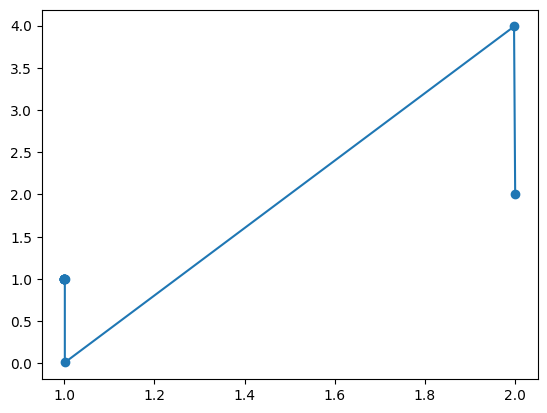

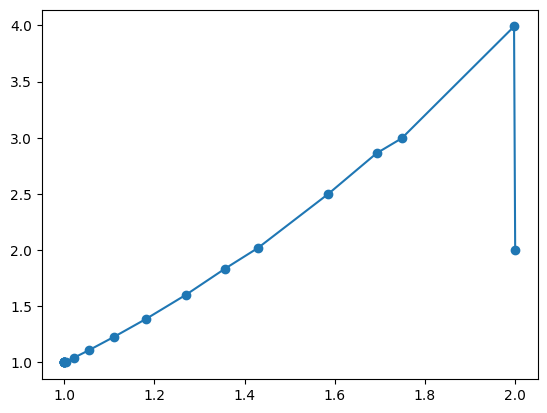

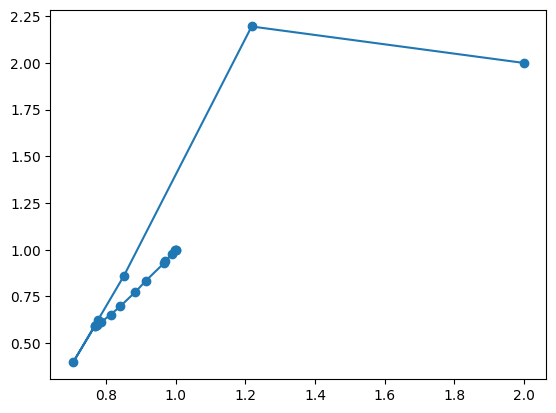

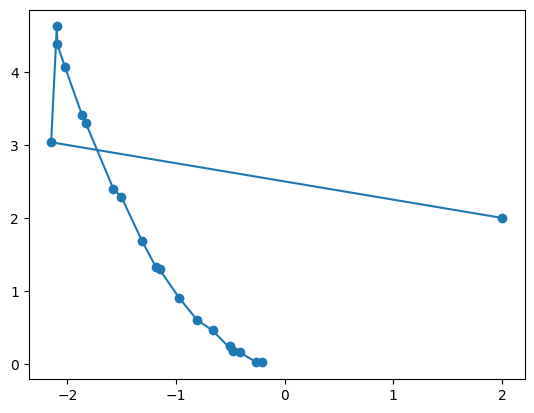

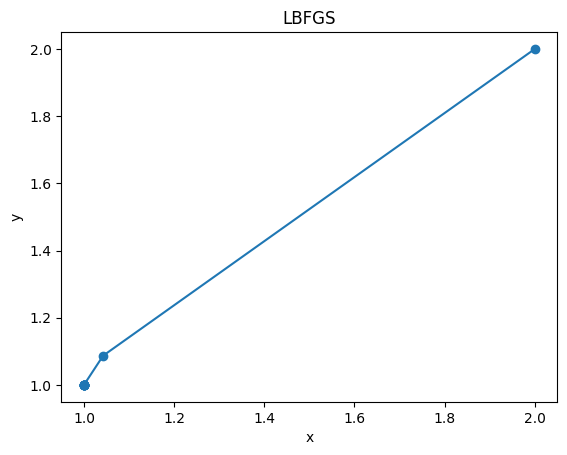

In [211]:
import matplotlib.pyplot as plt

for data, label in zip(datasets, labels):
    xs = [p[0] for p in data]
    ys = [p[1] for p in data]

    n = len(data)

    plt.figure()

    plt.plot(xs, ys, alpha=alpha)
    plt.scatter(xs, ys, alpha=alpha)

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"{label}")
plt.show()